
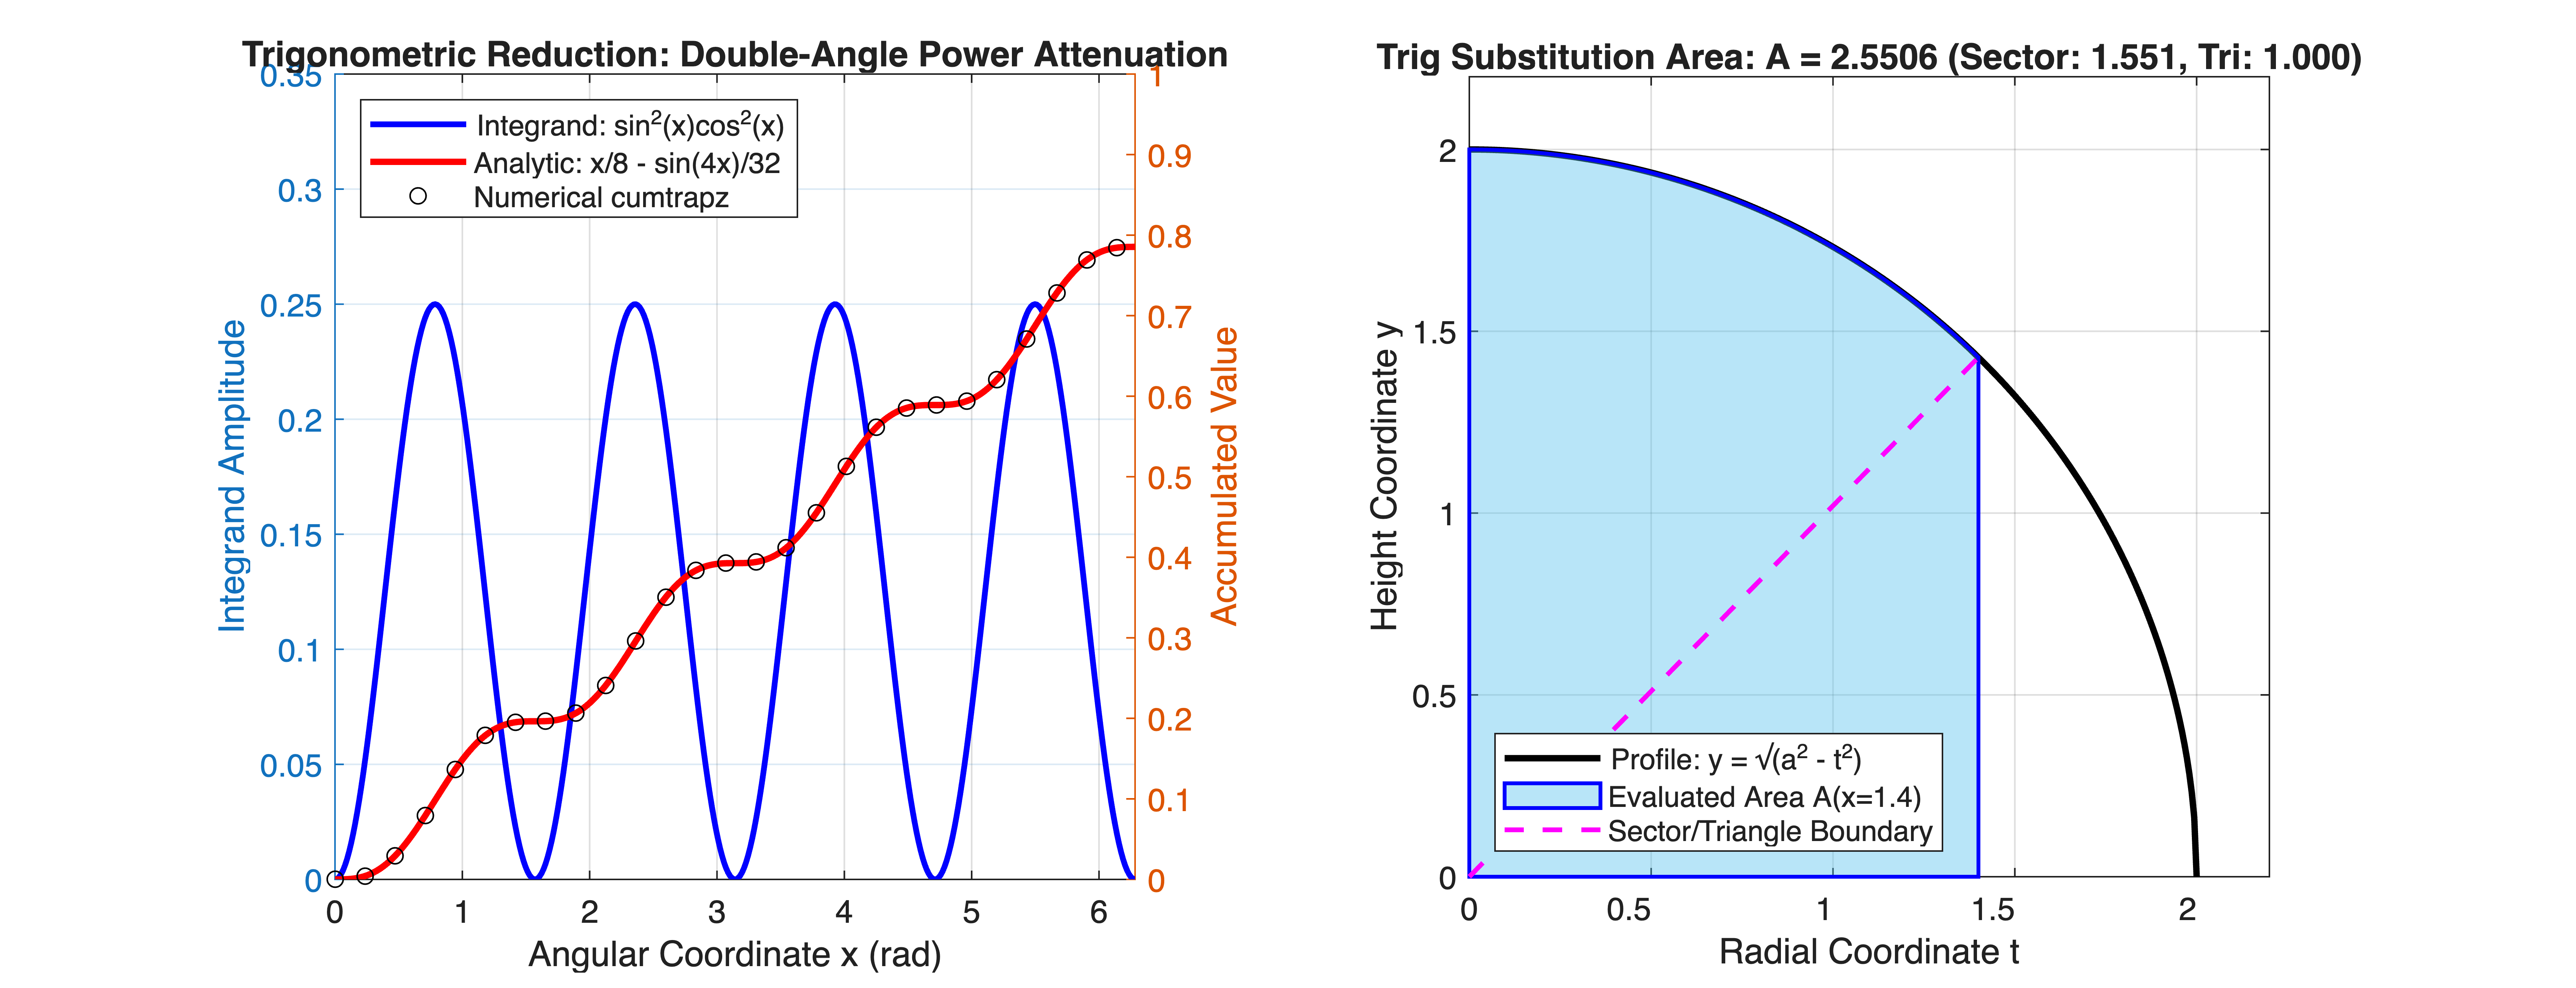

In [1]:
%% MIT 18.01 Lecture 26: Trigonometric Integrals & Substitution Simulation
% Mathematical Tool Application: Used for AC power harmonic reduction (Fourier analysis),
% trigonometric reduction in rotational kinematics, and exact analytical modeling
% of circular contact patch geometry via radical elimination.


clear; clc; close all;


%% Part 1: Even-Power Trig Reduction: \int sin^2(x)cos^2(x)dx (Method B)
% Integrand: f(x) = sin^2(x)*cos^2(x) = 0.25*sin^2(2x)
% Analytic Antiderivative: F(x) = (1/8)*x - (1/32)*sin(4*x)
f_trig = @(x) (sin(x).^2) .* (cos(x).^2);
F_analytic = @(x) (1.0 / 8.0) * x - (1.0 / 32.0) * sin(4.0 * x);


x_span = linspace(0, 2*pi, 400);
y_integrand = f_trig(x_span);
y_integral_exact = F_analytic(x_span);


% Numerical cumulative integration (Trapezoidal quadrature)
y_integral_num = cumtrapz(x_span, y_integrand);


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
yyaxis left;
plot(x_span, y_integrand, 'b-', 'LineWidth', 1.8, 'DisplayName', 'Integrand: sin^2(x)cos^2(x)'); hold on;
ylabel('Integrand Amplitude');
ylim([0, 0.35]);


yyaxis right;
plot(x_span, y_integral_exact, 'r-', 'LineWidth', 2.0, 'DisplayName', 'Analytic: x/8 - sin(4x)/32');
plot(x_span(1:15:end), y_integral_num(1:15:end), 'ko', 'MarkerSize', 5, ...
    'DisplayName', 'Numerical cumtrapz');
ylabel('Accumulated Value');
ylim([0, 1.0]);


grid on;
xlim([0, 2*pi]);
xlabel('Angular Coordinate x (rad)');
title('Trigonometric Reduction: Double-Angle Power Attenuation');
legend('Location', 'northwest');


%% Part 2: Circular Segment Area via Trig Substitution (t = a*sin(u))
% Problem: A(x) = \int_0^x sqrt(a^2 - t^2) dt = (a^2/2)*asin(x/a) + (x/2)*sqrt(a^2 - x^2)
subplot(1, 2, 2);
a_radius = 2.0;


% Target upper limit x_eval
x_eval = 1.4; % 0 < x_eval < a
t_span = linspace(0, a_radius, 300);
y_circle = sqrt(max(0, a_radius^2 - t_span.^2));


% Plot circular boundary
plot(t_span, y_circle, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Profile: y = \surd(a^2 - t^2)'); hold on;


% Fill integrated segment up to x_eval
t_fill = linspace(0, x_eval, 150);
y_fill = sqrt(a_radius^2 - t_fill.^2);
patch([0, t_fill, x_eval, 0], [0, y_fill, 0, 0], [0.3, 0.75, 0.93], ...
    'FaceAlpha', 0.4, 'EdgeColor', 'b', 'LineWidth', 1.2, ...
    'DisplayName', sprintf('Evaluated Area A(x=%.1f)', x_eval));


% Decomposition: Circular sector vs. Triangle
theta_eval = asin(x_eval / a_radius);
sector_area = 0.5 * (a_radius^2) * theta_eval;
triangle_area = 0.5 * x_eval * sqrt(a_radius^2 - x_eval^2);
total_area_analytic = sector_area + triangle_area;


% Plot geometric separation line from origin to circle edge
plot([0, x_eval], [0, sqrt(a_radius^2 - x_eval^2)], 'm--', 'LineWidth', 1.5, ...
    'DisplayName', 'Sector/Triangle Boundary');


grid on; axis equal;
xlim([0, a_radius + 0.2]); ylim([0, a_radius + 0.2]);
xlabel('Radial Coordinate t');
ylabel('Height Coordinate y');
title(sprintf('Trig Substitution Area: A = %.4f (Sector: %.3f, Tri: %.3f)', ...
    total_area_analytic, sector_area, triangle_area));
legend('Location', 'southwest');